<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Duplicates Lab**


Estimated time needed: **30** minutes


## Introduction


Data wrangling is a critical step in preparing datasets for analysis, and handling duplicates plays a key role in ensuring data accuracy. In this lab, you will focus on identifying and removing duplicate entries from your dataset. 


## Objectives


In this lab, you will perform the following:


1. Identify duplicate rows in the dataset and analyze their characteristics.
2. Visualize the distribution of duplicates based on key attributes.
3. Remove duplicate values strategically based on specific criteria.
4. Outline the process of verifying and documenting duplicate removal.


## Hands on Lab


Install the needed library


In [1]:
!pip install pandas
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 86.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 170.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 31.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 133.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 164.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]


Import pandas module


In [2]:
import pandas as pd

Import matplotlib


In [3]:
import matplotlib.pyplot as plt

## **Load the dataset into a dataframe**


<h2>Read Data</h2>
<p>
We utilize the <code>pandas.read_csv()</code> function for reading CSV files. However, in this version of the lab, which operates on JupyterLite, the dataset needs to be downloaded to the interface using the provided code below.
</p>


Load the data into a pandas dataframe:



In [4]:
df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv")

## Identify and Analyze Duplicates


### Task 1: Identify Duplicate Rows
1. Count the number of duplicate rows in the dataset.
3. Display the first few duplicate rows to understand their structure.


In [5]:
dups_row = df.duplicated()
print("Total of duplicates row:", dups_row.sum())

Total of duplicates row: 0

In [6]:
df[dups_row].head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat


### Task 2: Analysis of Duplicate Response Patterns
1. Identify duplicate response patterns based on selected columns such as MainBranch, Employment, and RemoteWork.
2. Clarify that these represent multiple respondents with identical answers rather than duplicate records. Analyse which other columns frequently share identical values within these response-pattern groups.
   

In [7]:
##Identify duplicate response patterns based on selected columns such as MainBranch, Employment, and RemoteWork

pattern_cols = ['MainBranch', 'Employment', 'RemoteWork']

print("Duplicate rows (all columns):", df.duplicated().sum())
print("The unique of ResponseId:", df['ResponseId'].is_unique)

pattern_counts = (
    df.groupby(pattern_cols, dropna=False)
    .size()
    .reset_index(name='n_respondents')
    .sort_values('n_respondents', ascending=False)
    .reset_index(drop=True))

df['shares_pattern'] = df.duplicated(subset=pattern_cols, keep=False)

print("\nTotal of Unique Pattern:", len(pattern_counts))
print("Respondent who shares pattern:", df['shares_pattern'].sum())
pattern_counts.head()


Duplicate rows (all columns): 0
The unique of ResponseId: True

Total of Unique Pattern: 561
Respondent who shares pattern: 65270

,MainBranch,Employment,RemoteWork,n_respondents
0,I am a developer by profession,"Employed, full-time","Hybrid (some remote, some in-person)",15286
1,I am a developer by profession,"Employed, full-time",Remote,12191
2,I am a developer by profession,"Employed, full-time",In-person,7118
3,I am a developer by profession,"Independent contractor, freelancer, or self-em...",Remote,2814
4,I am a developer by profession,"Employed, full-time;Independent contractor, fr...",Remote,1754


In [8]:
##Analyse which other columns frequently share identical values within these response-pattern groups

other_cols = [c for c in df.columns
              if c not in pattern_cols + ['ResponseId','shares_pattern']]

def mode_share(s):
    return s.value_counts(normalize=True, dropna=False).iloc[0]

consistency = (
    df[df['shares_pattern']]
    .groupby(pattern_cols, dropna=False)[other_cols]
    .agg(mode_share)
    .mean()
    .sort_values(ascending=False)
)

consistency.head()

Check                         1.000000
AINextMuch less integrated    0.967937
AINextLess integrated         0.941703
ConvertedCompYearly           0.841922
ICorPM                        0.817817
dtype: float64

### Task 3: Visualize Shared Response Patterns
1. Create visualizations to show the distribution of shared response patterns across different categories.
2. Use bar charts or pie charts to represent the distribution of respondents who share identical values for MainBranch, Employment, and RemoteWork, grouped by Country and Employment.


In [9]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.

/tmp/ipykernel_300/515116138.py:16: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()

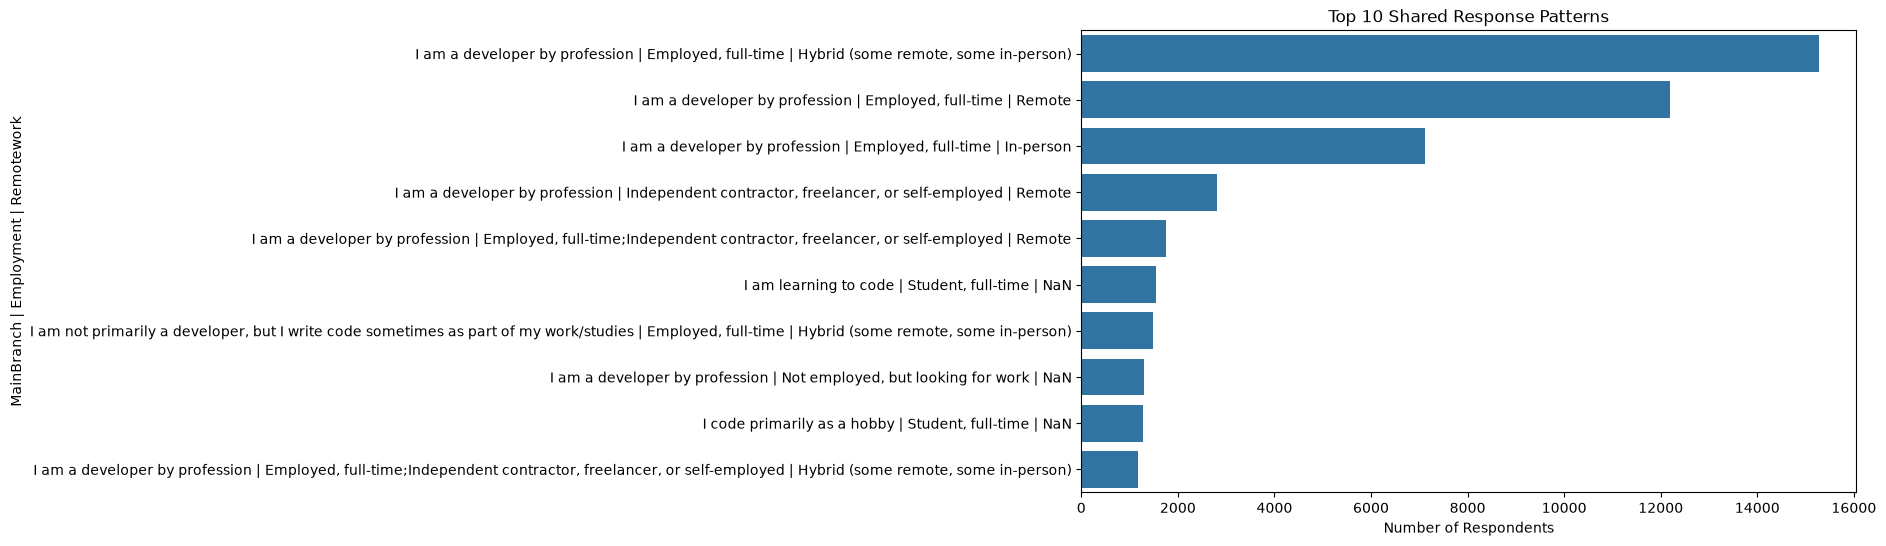

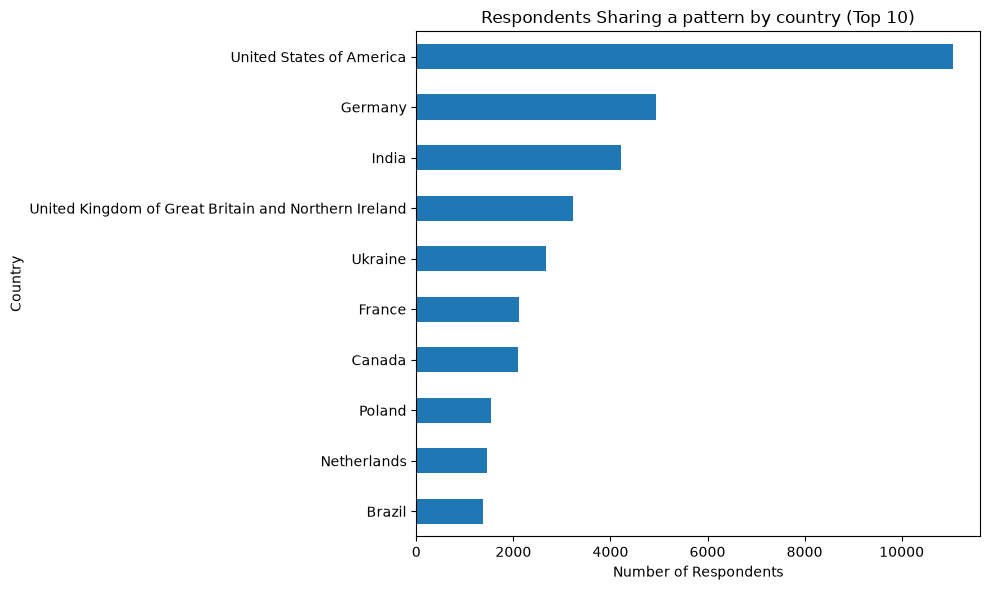

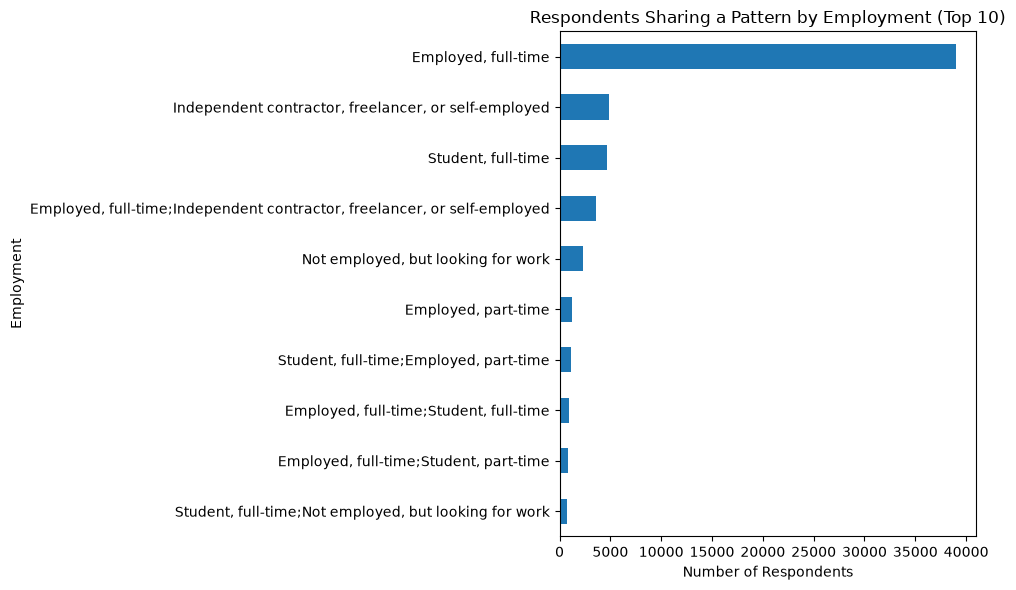

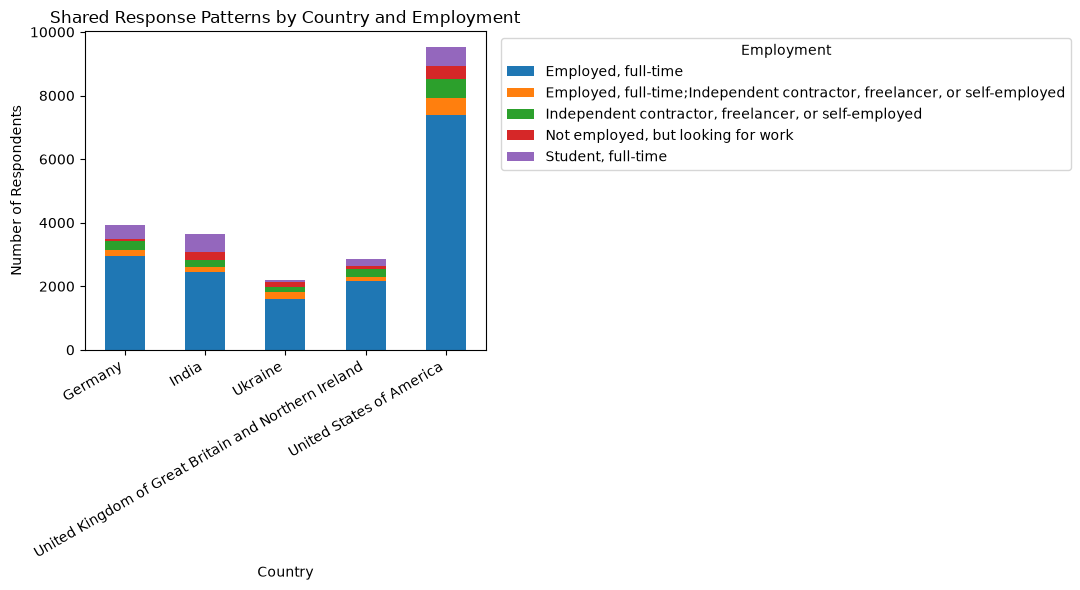

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

shared = df[df['shares_pattern']]

# TOP 10 most common response pattern
top_pattern = pattern_counts.head(10).copy()
top_pattern['label'] = (
    top_pattern[pattern_cols].fillna('NaN').astype(str).agg(' | '.join, axis=1)
)
plt.figure(figsize=(10, 6))
sns.barplot(data=top_pattern, y='label', x='n_respondents')
plt.title('Top 10 Shared Response Patterns')
plt.xlabel('Number of Respondents')
plt.ylabel('MainBranch | Employment | Remotework')
plt.tight_layout()
plt.show()

# Top 10 Respondents sharing a pattern, by country 
plt.figure(figsize=(10,6))
shared['Country'].value_counts().head(10).sort_values().plot(kind='barh')
plt.title('Respondents Sharing a pattern by country (Top 10)')
plt.xlabel('Number of Respondents')
plt.tight_layout()
plt.show()

# Respondents sharing a pattern, by Employment
plt.figure(figsize=(10,6))
shared['Employment'].value_counts().head(10).sort_values().plot(kind='barh')
plt.title('Respondents Sharing a Pattern by Employment (Top 10)')
plt.xlabel('Number of Respondents')
plt.tight_layout()
plt.show()

# Combine view: Country x Employment (Top 5 x Top 5)
top_c = shared['Country'].value_counts().head(5).index
top_e = shared['Employment'].value_counts().head(5).index
sub = shared[shared['Country'].isin(top_c) & shared['Employment'].isin(top_e)]

ct = pd.crosstab(sub['Country'], sub['Employment'])
ct.plot(kind='bar', stacked=True, figsize=(11, 6))
plt.title('Shared Response Patterns by Country and Employment')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Employment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Task 4: Evaluate Duplicate Handling Strategy
1. Analyse the dataset to determine which column(s) define record uniqueness.
2. Assess whether removing rows based on a subset of columns (rather than complete row duplication) is appropriate.
Justify your decision with reference to the structure and purpose of the dataset.


In [11]:
print("ResponseId is unique:", df['ResponseId'].is_unique)
print("Full duplicate rows:", df.duplicated().sum())
print("Total rows:", len(df))
print("Rows remaining after drop_duplicates(subset=pattern_cols):",
      len(df.drop_duplicates(subset=pattern_cols)))

ResponseId is unique: TrueFull duplicate rows: 0
Total rows: 65437
Rows remaining after drop_duplicates(subset=pattern_cols): 561

**1. Columns that define record uniqueness**

`ResponseId` is the only column that uniquely identifies a record: it is unique
for every row (`is_unique = True`), and there are 0 fully duplicated rows.
Each row represents one survey respondent. Columns such as `MainBranch`,
`Employment`, and `RemoteWork` are categorical answers with a limited set of
possible values, so they cannot identify an individual respondent on their own.

**2. Is removing rows based on a subset of columns appropriate?**

No. Dropping duplicates based on `MainBranch`, `Employment`, and `RemoteWork`
would reduce 65,437 records to only 561, removing about 99% of the data.
Rows that share these values are not duplicate records. They are different
respondents who happen to give the same answers, and they differ in other
columns (e.g., Country, ConvertedCompYearly, years of experience).

The dataset is a survey, so its purpose is to capture the variety of many
respondents' answers. Removing respondents who share common answers would
distort distributions, introduce bias, and destroy the analytical value of the data.

**3. Decision**

No rows should be removed. The dataset has no complete duplicates and
`ResponseId` is unique, so it is already free of true duplicates.
Subset-based removal would only be justified if the subset contained a true
identifier or there was evidence of repeated submissions by the same person.

## Verify and Document Duplicate Removal Process


### Task 5: Documentation
1. Document the process of identifying and removing duplicates.


**Process of identifying and removing duplicates**

1. **Checked for complete duplicate rows.** Using `df.duplicated().sum()`, I found
   0 fully duplicated rows, so there are no exact duplicate records.
2. **Verified the record identifier.** `df['ResponseId'].is_unique` returned `True`,
   confirming that every row is a distinct survey response.
3. **Analysed response patterns.** I grouped respondents by `MainBranch`, `Employment`,
   and `RemoteWork`, which produced 561 unique patterns. 65,270 of 65,437
   respondents share a pattern with at least one other respondent.
4. **Clarified what these patterns represent.** They are different respondents who gave
   identical answers on these three questions, not duplicate records. Other columns
   (e.g., Country, ConvertedCompYearly) differ between them.
5. **Visualised the shared patterns** by Country and Employment to see where they concentrate.
6. **Evaluated a subset-based removal strategy.** `drop_duplicates(subset=pattern_cols)`
   would reduce the dataset from 65,437 rows to 561, removing about 99% of the data.
7. **Decision and verification.** No rows were removed. The row count before and after
   is the same (65,437), and `ResponseId` remains unique.

2. Explain the reasoning behind selecting specific columns for identifying and removing duplicates.


**Reasoning for the column selection**

- **`ResponseId` (identifier).** It is the only column that identifies an individual
  record, so it is the right column to test uniqueness. Because it is unique, there are
  no true duplicates.
- **All columns (`df.duplicated()`).** Checking every column is the strictest test for
  exact duplicate records. It returned 0, meaning no row is repeated.
- **`MainBranch`, `Employment`, `RemoteWork` (pattern columns).** I selected these
  because they are categorical survey questions answered by almost every respondent, so
  they work well for studying how often respondents give the same answers. They are
  suitable for **pattern analysis**, but not for **removing duplicates**, because they
  have few possible values, and many different people will naturally share them.
- **Why not remove by subset.** Deleting rows based on these columns would remove
  valid respondents and distort the data. A subset should only be used for removal when
  it contains a true identifier or when there is evidence of repeated submissions.

### Summary and Next Steps
**In this lab, you focused on identifying and analyzing duplicate rows within the dataset.**

- You employed various techniques to explore the nature of duplicates and applied strategic methods for their removal.
- For additional analysis, consider investigating the impact of duplicates on specific analyses and how their removal affects the results.
- This version of the lab is more focused on duplicate analysis and handling, providing a structured approach to deal with duplicates in a dataset effectively.


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-11- 05|1.3|Madhusudhan Moole|Updated lab|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-09-24|1.1|Madhusudhan Moole|Updated lab|
|2024-09-23|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
